In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import auc
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

from tqdm.auto import tqdm

### Data preparation

In [2]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

In [3]:
!wget $data -O data_home_4.csv

--2026-10-17 09:48:41--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data_home_4.csv’

data_home_4.csv     100%[===================>] 272.21K  --.-KB/s    in 0.003s  

2026-10-17 09:48:41 (98.4 MB/s) - ‘data_home_4.csv’ saved [278746/278746]



In [4]:
df = pd.read_csv('data_home_4.csv')
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
df = df.fillna({
    col: 'NA' if df[col].dtype == 'str' else 0.0
    for col in df.columns
})

In [8]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [9]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [10]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [11]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
categorical = ['lead_source', 'industry', 'employment_status', 'location']

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 
* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that

Which numerical variable has the highest AUC?

In [12]:
results = []

for i in numerical:
    
    y_pred = df_train[i]
    area_under_curve_score = roc_auc_score(y_train, y_pred)
    results.append({'feature': i, 'AUC': area_under_curve_score})

df_results = pd.DataFrame(results)

print(df_results)
print("")
print("Feature with the highest AUC:", df_results.loc[df_results['AUC'].idxmax(), 'feature'])

                    feature       AUC
0             annual_income  0.608198
1  number_of_courses_viewed  0.722989
2         interaction_count  0.764920
3                lead_score  0.788225

Feature with the highest AUC: lead_score


### Question 2: model AUC

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression.

What's the AUC of this model on the validation dataset? 

In [13]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')                               
X_train = dv.fit_transform(train_dict)                                                                 

model = LogisticRegression(solver = 'liblinear', C = 1.0, max_iter = 1000)                                                                          
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')                                   
X_val = dv.transform(val_dict)       

y_pred = model.predict_proba(X_val)[:, 1]           

area_under_curve_score = roc_auc_score(y_val, y_pred)

print("AUC is:", round(area_under_curve_score, 3))

AUC is: 0.732


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect?

In [14]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))
    
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores

,threshold,tp,fp,fn,tn,precision,recall
0,0.00,586,414,0,0,0.586,1.000000
1,0.01,586,414,0,0,0.586,1.000000
2,0.02,586,414,0,0,0.586,1.000000
3,0.03,586,414,0,0,0.586,1.000000
4,0.04,586,414,0,0,0.586,1.000000
...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,1.000,0.001706
97,0.97,0,0,586,414,NaN,0.000000
98,0.98,0,0,586,414,NaN,0.000000
99,0.99,0,0,586,414,NaN,0.000000


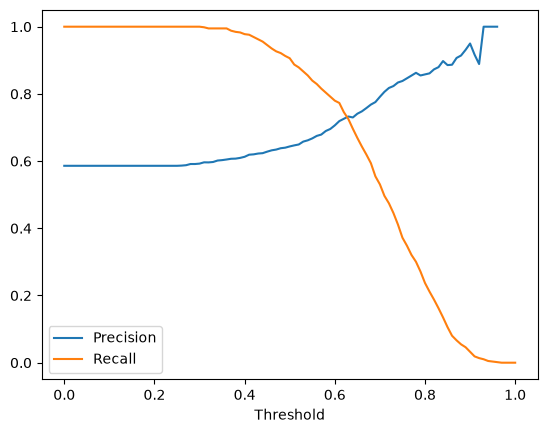

In [15]:
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')

plt.xlabel('Threshold')
#plt.ylabel('Score')
plt.legend()
plt.show()

In [16]:
df_scores['diff'] = abs(df_scores.precision - df_scores.recall)
idx = df_scores['diff'].idxmin()
print(df_scores.loc[idx, ['threshold', 'precision', 'recall']])

threshold    0.630000
precision    0.732759
recall       0.725256
Name: 63, dtype: float64


### Question 4: F1 score 

Precision and recall are conflicting - when one grows, the other goes down. 

That's why they are often combined into the F1 score - a metrics that takes into account both.

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

In [17]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))
    
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['f1'] = 2 * ((df_scores['precision']* df_scores['recall'])/(df_scores['precision'] + df_scores['recall']))

df_scores

,threshold,tp,fp,fn,tn,precision,recall,f1
0,0.00,586,414,0,0,0.586,1.000000,0.738966
1,0.01,586,414,0,0,0.586,1.000000,0.738966
2,0.02,586,414,0,0,0.586,1.000000,0.738966
3,0.03,586,414,0,0,0.586,1.000000,0.738966
4,0.04,586,414,0,0,0.586,1.000000,0.738966
...,...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,1.000,0.001706,0.003407
97,0.97,0,0,586,414,NaN,0.000000,NaN
98,0.98,0,0,586,414,NaN,0.000000,NaN
99,0.99,0,0,586,414,NaN,0.000000,NaN


In [18]:
idx1 = df_scores['f1'].idxmax()
print(df_scores.loc[idx1, ['threshold', 'f1']])

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64


### Question 5: 5-Fold CV standard deviation

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds: `KFold(n_splits=5, shuffle=True, random_state=1)`
* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

In [25]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver = 'liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [26]:
dv, model = train(df_train, y_train, C = 1.0)

In [27]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [29]:
kfold = KFold(n_splits = 5, shuffle = True, random_state = 1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print("Standard deviation across different folds is: ", np.std(scores))

Standard deviation across different folds is:  0.006853233151022138


### Question 6: Hyperparameter tuning, best C

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

In [30]:
results = []

for C in tqdm([0.000001, 0.001, 1]):

    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    mean_score = np.mean(scores)
    std_score = np.std(scores)

    print('C=%s %.3f +- %.3f' % (C, mean_score, std_score))

    results.append({'C': C, 'mean': round(mean_score, 3), 'std': round(std_score, 3)})

df_results = pd.DataFrame(results)

# Highest mean AUC; in case of ties, lowest std; then smallest C
df_results = df_results.sort_values(by = ['mean', 'std', 'C'], ascending=[False, True, True])

print("The value of C which leads to the best mean ROC AUC is: ", df_results.iloc[0]['C'])

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
The value of C which leads to the best mean ROC AUC is:  0.001
